# Milestone 1: playing time after a transfer

> **Notes for the write-up** (replace this cell with your own text):
>
> - The question: for a player joining a new club, predict his league playing-time share there in the next 12 months (league minutes / (90 × the club's league games), between 0 and 1).
> - Data: Wyscout 2017/18 events joined to Transfermarkt; one row = one transfer.
> - Running: top to bottom; the first two cells download the data and build the tables if they're missing.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.data.download_data import download_all
download_all()   # skips files you already have

Wyscout -> /home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw/wyscout
  players.json: already present, skipping
  teams.json: already present, skipping
  matches_*.json: already present, skipping
  events_*.json: already present, skipping
Transfermarkt -> /home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw/transfermarkt
  players.csv.gz: already present, checksum OK, skipping
  transfers.csv.gz: already present, checksum OK, skipping
  appearances.csv.gz: already present, checksum OK, skipping
  games.csv.gz: already present, checksum OK, skipping
  clubs.csv.gz: already present, checksum OK, skipping


  player_valuations.csv.gz: already present, checksum OK, skipping
ClubElo -> /home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw/clubelo
  EloRatings.csv: already present, checksum OK, skipping
Understat -> /home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw/understat
  players_epl_14-15.csv: already present, skipping
  shots_epl_14-15.csv: already present, skipping
  players_epl_15-16.csv: already present, skipping
  shots_epl_15-16.csv: already present, skipping
  players_epl_16-17.csv: already present, skipping
  shots_epl_16-17.csv: already present, skipping
  players_epl_17-18.csv: already present, skipping
  shots_epl_17-18.csv: already present, skipping
  players_epl_18-19.csv: already present, skipping
  shots_epl_18-19.csv: already present, skipping
  players_epl_19-20.csv: already present, skipping
  shots_epl_19-20.csv: already present, skipping
  players_epl_20-21.csv: already present, skipping
  shots_epl_20-21.csv: already presen

PosixPath('/home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error

from src.pipelines import build_transfers
from src.features import player_roles

DATA = ROOT / "data/processed"
if not (DATA / "transfers_joined.csv").exists() or not (DATA / "transfer_funnel.csv").exists():
    build_transfers.main()   # matching + label + funnel, ~1 min the first time

data = pd.read_csv(DATA / "transfers_joined.csv", parse_dates=["transfer_date"])
split = pd.read_csv(DATA / "split.csv", parse_dates=["transfer_date"])
funnel = pd.read_csv(DATA / "transfer_funnel.csv")
link = pd.read_csv(DATA / "wyscout_tm_link.csv")
players = build_transfers.load_player_features()

roles = player_roles.assign_roles(players, player_roles.K_BY_POSITION, player_roles.ROLE_ANCHORS)
data = data.merge(roles[["wy_id", "role"]], on="wy_id", how="left")

## 1 · The data

In [3]:
data[["player_name", "from_club_name", "to_club_name", "transfer_date", "position",
      "age", "log_mv", "prev_share_tm", "wy_share", "y"]].head()

,player_name,from_club_name,to_club_name,transfer_date,position,age,log_mv,prev_share_tm,wy_share,y
0,Takuma Asano,Stuttgart,Arsenal,2018-06-30,Attack,23.635866,14.508658,0.234641,0.234967,0.000000
1,Alex Meret,SPAL,Udinese,2018-06-30,Goalkeeper,21.273101,16.300417,0.338889,0.339181,0.000000
2,Leonardo Spinazzola,Atalanta,Juventus,2018-06-30,Defender,25.264887,16.300417,0.440643,0.440058,0.174854
3,Lorenzo Venuti,Benevento,Fiorentina,2018-06-30,Defender,23.216975,14.220976,0.697953,0.697368,0.000000
4,Marco Sportiello,Fiorentina,Atalanta,2018-06-30,Goalkeeper,26.138261,15.607270,0.936257,0.960819,0.000000


In [4]:
print(funnel.to_string(index=False))
print(f"\nmatched {len(link)} of {len(players)} Wyscout players to Transfermarkt ({len(link) / len(players):.1%})")

                                       step     n
Wyscout players with 2017/18 league minutes  2561
           linked to a Transfermarkt player  2523
    transfers of linked players (all years) 14822
             dated 2018-05-15 to 2019-02-15   795
                         club-to-club moves   791
                     excluding loan returns   522
                      first move per player   464
     destination club covered (>= 10 games)   358
          >= 450 Wyscout minutes  ->  FINAL   276

matched 2523 of 2561 Wyscout players to Transfermarkt (98.5%)


count    276.000
mean       0.489
std        0.290
min        0.000
25%        0.231
50%        0.533
75%        0.730
max        1.000
Name: y, dtype: float64
never played: 0.054   played every minute: 0.014


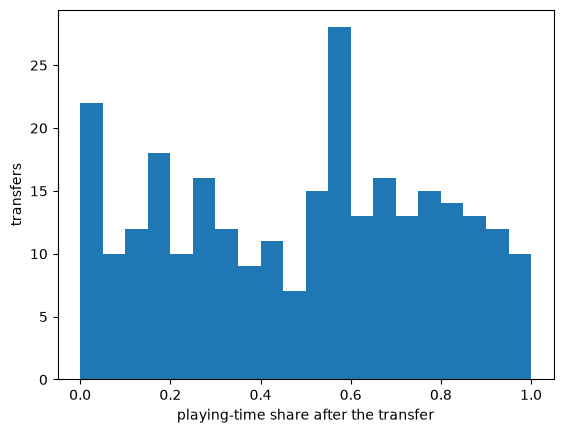

In [5]:
print(data.y.describe().round(3))
print("never played:", round((data.y == 0).mean(), 3), "  played every minute:", round((data.y == 1).mean(), 3))

plt.hist(data.y, bins=20)
plt.xlabel("playing-time share after the transfer")
plt.ylabel("transfers")
plt.show()

In [6]:
print("players:", data.player_id.nunique())
print("destination clubs:", data.to_club_id.nunique())
print("selling clubs:", data.from_club_id.nunique())

players: 276
destination clubs: 111
selling clubs: 100


> **Notes for the write-up** (replace this cell with your own text):
>
> - One row per transfer; the funnel shows how 2,561 Wyscout players become 276 transfers we can label.
> - Matching rate 98.5% (dob + fuzzy name).
> - The label is a number, not a class, so 'label balance' = its distribution: mean ~0.49, 5% never played.
> - Groups: every player appears once (we keep his first move), ~111 destination clubs.

## 2 · The split

In [7]:
train, test = train_test_split(data, test_size=0.2, random_state=42)

# same split as the one saved in split.csv (shared by every notebook)
saved_test = split[split.split == "test"]
print("same as split.csv:", set(test.player_id) == set(saved_test.player_id))

print("train", len(train), "  test", len(test))
print("mean y in train", round(train.y.mean(), 3), "  in test", round(test.y.mean(), 3))
print("players on both sides:", len(set(train.player_id) & set(test.player_id)), " <- must be 0")
print("destination clubs on both sides:", len(set(train.to_club_id) & set(test.to_club_id)))

same as split.csv: True
train 220   test 56
mean y in train 0.484   in test 0.512
players on both sides: 0  <- must be 0
destination clubs on both sides: 32


> **Notes for the write-up** (replace this cell with your own text):
>
> - We split on the player: each player is in the data once, so no player can be on both sides.
> - Caveat: destination clubs repeat across train and test (about 32 clubs). Our features don't include the club, but transfers to the same club compete for the same minutes. Say whether you think this matters.
> - Later (several seasons) the same player can appear more than once, so we'll split by player and by time.

### What a leaky feature does

In [8]:
NUM = ["age", "log_mv", "prev_share_tm", "wy_share", "pass_acc"] + [c for c in data.columns if c.endswith("_p90")]
CAT = ["position"]

def linreg(num):
    prep = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num),
        (OneHotEncoder(handle_unknown="ignore"), CAT))
    return make_pipeline(prep, LinearRegression())

# the mistake: market value ONE YEAR AFTER the transfer instead of at the transfer
vals = pd.read_csv(ROOT / "data/raw/transfermarkt/player_valuations.csv.gz", parse_dates=["date"]).sort_values("date")
later = data[["player_id"]].assign(date=data.transfer_date + pd.Timedelta(days=365)).reset_index().sort_values("date")
later = pd.merge_asof(later, vals[["player_id", "date", "market_value_in_eur"]], on="date", by="player_id")
data["log_mv_later"] = np.log1p(later.set_index("index").market_value_in_eur)
train, test = data.loc[train.index], data.loc[test.index]

leaky = [c if c != "log_mv" else "log_mv_later" for c in NUM]
for name, num in [("value at the transfer", NUM), ("value one year later (leak)", leaky)]:
    m = linreg(num).fit(train[num + CAT], train.y)
    print(f"{name:30s} test MSE {mean_squared_error(test.y, m.predict(test[num + CAT])):.4f}")
print(f"{'always predict the average':30s} test MSE {mean_squared_error(test.y, np.full(len(test), train.y.mean())):.4f}")

value at the transfer          test MSE 0.1012
value one year later (leak)    test MSE 0.0697
always predict the average     test MSE 0.0973


> **Notes for the write-up** (replace this cell with your own text):
>
> - With the leaky column the model 'beats' the average (test MSE ~0.070 vs ~0.097). Same model, one column changed.
> - Why it's wrong: the market value a year later partly records how much he played.
> - Our rule: every feature is dated on or before the transfer.

## 3 · The model

In [9]:
model = linreg(NUM).fit(train[NUM + CAT], train.y)
n_params = model[-1].coef_.size + 1
print("linear regression, trainable parameters:", n_params, " for", len(train), "training rows")

linear regression, trainable parameters: 20  for 220 training rows


> **Notes for the write-up** (replace this cell with your own text):
>
> - Simplest model that could work: linear regression on what a scout knows at the transfer date: age, market value, position, playing time before the move, and 2017/18 per-90 stats.
> - 20 parameters for 220 rows.

## 4 · The error, and the baselines

In [10]:
METRIC = "MSE"
WHY = ("A big miss, expecting a starter who then barely plays, costs a club much more than a small one, "
       "so squared errors fit the problem.")   # TODO: rewrite in your own words (at least 12 words)
assert len(WHY.split()) >= 12
print("we report", METRIC, "because:", WHY)

we report MSE because: A big miss, expecting a starter who then barely plays, costs a club much more than a small one, so squared errors fit the problem.


In [11]:
mean_y = train.y.mean()
preds = {
    "always predict the average":  np.full(len(test), mean_y),
    "plays as much as last year":  test.prev_share_tm.fillna(mean_y).clip(0, 1),
    "average for his role":        test.role.map(train.groupby("role").y.mean()).fillna(mean_y),
    "linear regression":           model.predict(test[NUM + CAT]),
}
table = pd.DataFrame({
    "test MSE": {k: mean_squared_error(test.y, p) for k, p in preds.items()},
    "overestimated by >= 0.25": {k: f"{(p - test.y >= 0.25).sum()} of {len(test)}" for k, p in preds.items()},
})

# cross-validation on the training rows, for the two models that need fitting
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)
cv_lr = -cross_val_score(linreg(NUM), train[NUM + CAT], train.y, cv=cv, scoring="neg_mean_squared_error")
cv_mean = [mean_squared_error(train.y.iloc[va], np.full(len(va), train.y.iloc[tr].mean()))
           for tr, va in cv.split(train)]
table["CV MSE"] = pd.Series({"always predict the average": np.mean(cv_mean), "linear regression": cv_lr.mean()})
table.round(4)

,test MSE,overestimated by >= 0.25,CV MSE
always predict the average,0.0973,16 of 56,0.0815
plays as much as last year,0.1533,15 of 56,NaN
average for his role,0.1120,14 of 56,NaN
linear regression,0.1012,16 of 56,0.0865


> **Notes for the write-up** (replace this cell with your own text):
>
> - We picked MSE before training (proposal). The 'overestimated' column is because overestimating playing time is the costly mistake for a club.
> - Result: nothing beats always predicting the average (test ~0.097, CV ~0.082). 'Plays as much as last year' is clearly the worst (~0.15).
> - Why (in your words): small data (220 rows); the features describe only the player, not the club (competition for places, manager); last year's minutes don't carry over after a move.
> - This is fine to report; it sets the bar for next milestones: beat CV MSE ~0.082.

## 5 · Optimisation checks

In [12]:
# twenty-row check: fit on 20 training rows spread across y, test on the same 20
twenty = train.sort_values("y").iloc[np.linspace(0, len(train) - 1, 20).astype(int)]
tiny = linreg(NUM).fit(twenty[NUM + CAT], twenty.y)
print("MSE on the same 20 rows:", round(mean_squared_error(twenty.y, tiny.predict(twenty[NUM + CAT])), 4),
      "  (variance of those 20:", round(twenty.y.var(ddof=0), 4), ")")

MSE on the same 20 rows: 0.002   (variance of those 20: 0.0894 )


> **Notes for the write-up** (replace this cell with your own text):
>
> - MSE 0.002 on the same 20 rows, against a variance of 0.089: it fits about 98% of their variation, so the wiring works.
> - Not exactly 0 because only 19 of the 20 parameters are independent (the position columns overlap with the intercept), one fewer than the 20 rows.

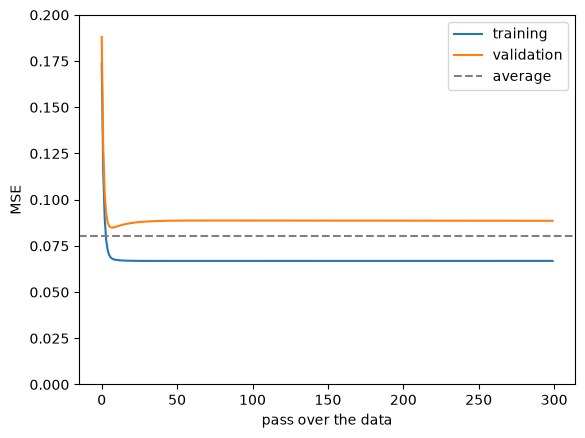

In [13]:
# training curve: the same linear model trained step by step with SGD
tr2, va = train_test_split(train, test_size=0.3, random_state=0)
prep = linreg(NUM)[0].fit(tr2[NUM + CAT])
X_tr, X_va = prep.transform(tr2[NUM + CAT]), prep.transform(va[NUM + CAT])

sgd = SGDRegressor(penalty=None, learning_rate="constant", eta0=0.002, random_state=0)
train_loss, val_loss = [], []
for step in range(300):
    sgd.partial_fit(X_tr, tr2.y)
    train_loss.append(mean_squared_error(tr2.y, sgd.predict(X_tr)))
    val_loss.append(mean_squared_error(va.y, sgd.predict(X_va)))

plt.plot(train_loss, label="training")
plt.plot(val_loss, label="validation")
plt.axhline(mean_squared_error(va.y, np.full(len(va), tr2.y.mean())), color="grey", ls="--", label="average")
plt.xlabel("pass over the data"); plt.ylabel("MSE"); plt.ylim(0, 0.2); plt.legend()
plt.show()

> **Notes for the write-up** (replace this cell with your own text):
>
> - Training MSE keeps going down (~0.17 to ~0.07).
> - Validation MSE is lowest after a few passes (~0.085) and never gets below the average line (~0.080): overfitting.

## 6 · Player roles (our one clustering)

In [14]:
print(roles.groupby(["position", "role"]).size())

famous = ["Sergio Ramos", "Sergio Busquets", "N. Kanté", "K. De Bruyne", "L. Messi", "H. Kane"]
names = roles.merge(players[["wy_id", "shortName", "wy_team"]], on="wy_id")
names[names.shortName.isin(famous)][["shortName", "wy_team", "role"]]

position  role                    
DF        Attacking full-back         154
          Ball-playing centre-back    151
          Defensive centre-back       217
          Defensive full-back         181
FW        Central striker             195
          Creative forward            100
          Wide support forward        108
GK        Goalkeeper                  135
MD        Attacking midfielder        153
          Ball-winning midfielder     189
          Deep-lying midfielder       182
          Wide midfielder             182
dtype: int64


,shortName,wy_team,role
29,Sergio Ramos,Real Madrid,Ball-playing centre-back
722,L. Messi,Barcelona,Creative forward
777,H. Kane,Tottenham Hotspur,Central striker
1265,Sergio Busquets,Barcelona,Deep-lying midfielder
1632,N. Kanté,Chelsea,Deep-lying midfielder
1641,K. De Bruyne,Manchester City,Attacking midfielder


In [15]:
data.groupby("role").y.agg(["count", "mean"]).sort_values("mean").round(3)

,count,mean
role,,
Attacking midfielder,20,0.366
Wide support forward,20,0.400
Defensive full-back,23,0.431
Attacking full-back,19,0.435
Wide midfielder,26,0.457
Creative forward,17,0.491
Ball-winning midfielder,36,0.504
Defensive centre-back,19,0.526
Ball-playing centre-back,19,0.538


> **Notes for the write-up** (replace this cell with your own text):
>
> - k-means within each position on 12 style features (passing, progression, shots, dribbles, duels, position on the pitch...); k chosen by stability, see notebook 03.
> - Famous players land where you'd expect. Caveat: stats depend on team possession, so Kanté is with Busquets.
> - Playing time by role is noisy (17–36 transfers per role); the 'average for his role' baseline doesn't beat the overall average.
> - Later use: describing team weaknesses in terms of roles.

## What worries us

> **Notes for the write-up** (replace this cell with your own text):
>
> - 4–5 sentences in your own words. Main worry: nothing beats the average with 276 transfers and player-only features, so we can't yet show that player–team fit matters.
> - What we'll do: a multi-season dataset (Transfermarkt + EA FC, ~2,800 transfers) and team features (style, weaknesses by role); first test: beat CV MSE ~0.082.

In [16]:
MILESTONE_1 = {
    "question":       "predict a transferred player's league playing-time share in his first 12 months",
    "n_examples":     len(data),
    "n_groups":       data.player_id.nunique(),
    "split_on":       "player",
    "label_mean":     round(data.y.mean(), 3),
    "metric":         METRIC,
    "baseline_name":  "always predict the average",
    "baseline_score": round(table.loc["always predict the average", "test MSE"], 4),
    "model_name":     "linear regression",
    "model_score":    round(table.loc["linear regression", "test MSE"], 4),
    "biggest_worry":  "nothing beats the average yet",   # TODO: one sentence in your own words
}
for k, v in MILESTONE_1.items():
    print(f"{k:<16} {v}")

question         predict a transferred player's league playing-time share in his first 12 months
n_examples       276
n_groups         276
split_on         player
label_mean       0.489
metric           MSE
baseline_name    always predict the average
baseline_score   0.0973
model_name       linear regression
model_score      0.1012
biggest_worry    nothing beats the average yet
